# 03 · Development factors and tail

**Question this notebook answers:** which age-to-age factors should drive the projections, and how much development is still to come after age 10?

In my first project I used a single all-year volume-weighted average without questioning it. Here every choice is compared with the alternatives and its impact on the reserve is measured, so the selection can be defended.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reserving import config as cfg, data as D, plots as PL

PL.setup()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 140

In [2]:
from reserving.factors import average_factors, factor_comparison, flag_outliers, fit_tail, cdfs
from reserving.diagnostics import outlier_list
from reserving.methods import chain_ladder

df = D.load_cas()
co = D.company(df, cfg.STUDY_GRCODE)
universe = D.backtest_universe(df)
ind = D.industry(df, exclude=cfg.STUDY_GRCODE, grcodes=universe)
paid, case = co.paid, co.case
paid_latest = paid.latest_diagonal()

def cl_unpaid(tri, ldf, tail):
    # total unpaid (ultimate - paid to date) from a chain ladder with the given factors
    return float((chain_ladder(tri, cdfs(ldf, tail))["ultimate"] - paid_latest).sum())

## 1. Link ratios and outliers

Cells are shaded by how far each link ratio sits from its column median (blue = below, red = above). Boxed values are flagged as outliers: more than 2.5 **robust** standard deviations from the median, using the median absolute deviation, so one extreme value can't hide itself by inflating the spread.

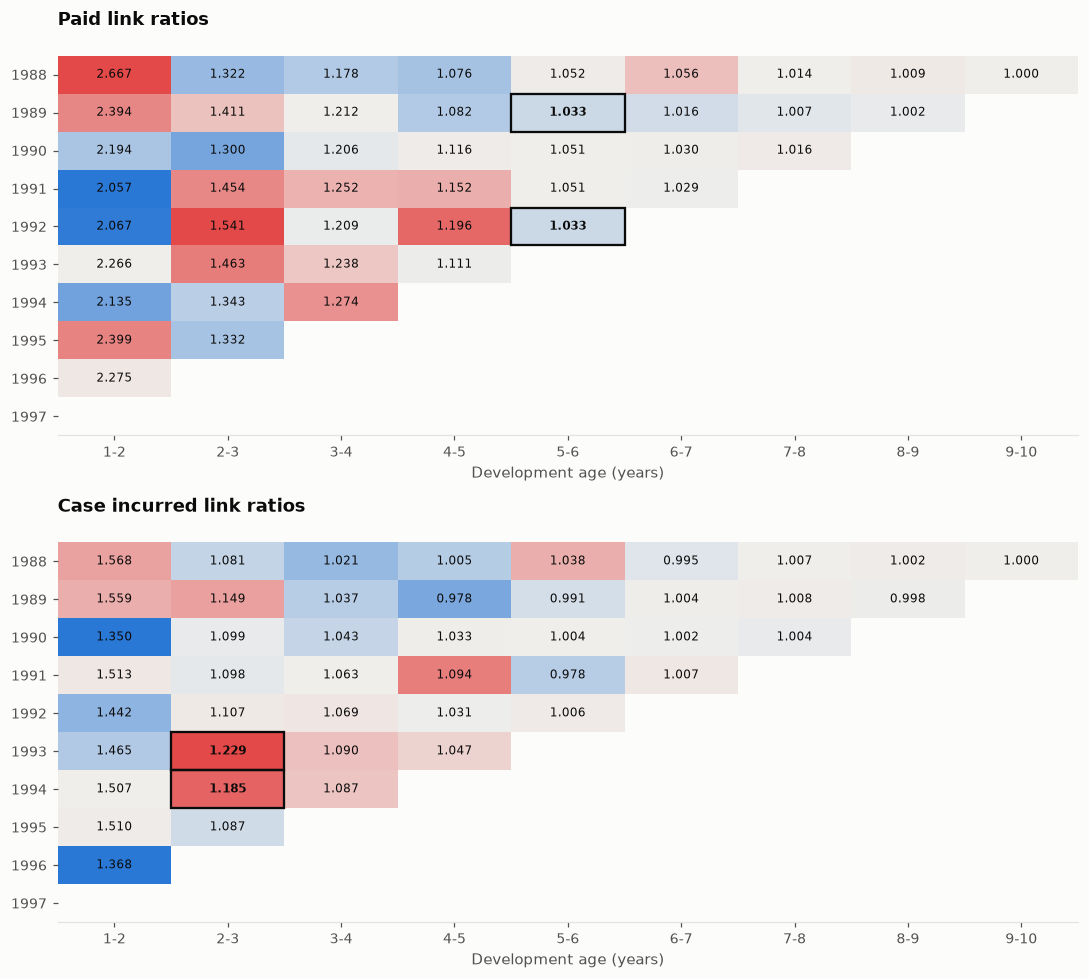

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9))
for ax, tri, name in [(axes[0], paid, "Paid"), (axes[1], case, "Case incurred")]:
    PL.link_ratio_heatmap(tri.link_ratios(), flag_outliers(tri, z=2.5), title=f"{name} link ratios", ax=ax)
fig.tight_layout()
PL.save(fig, "03_link_ratio_heatmaps")
plt.show()

In [4]:
out = pd.concat({
    "paid": outlier_list(flag_outliers(paid, z=2.5), paid.link_ratios()),
    "case": outlier_list(flag_outliers(case, z=2.5), case.link_ratios()),
}).droplevel(1)
out

,origin,age,link_ratio,age_median
paid,1989,5,1.033,1.051
paid,1992,5,1.033,1.051
case,1993,2,1.229,1.103
case,1994,2,1.185,1.103


### Should any be excluded?

* **Paid, 1989 and 1992 at age 5→6 (1.033 vs median 1.051).** Small deviations in a column where the ratios are tightly clustered. Immaterial; keep.
* **Case, 1993 and 1994 at age 2→3 (1.229 and 1.185 vs median ~1.10).** These matter. They are also the **two most recent observations** at that age, and notebook 02 found a calendar shift in the paid/case ratio starting at exactly this point.

Excluding a link ratio is justified when it reflects a **one-off** (a single large claim, a data error, a reinsurance commutation) that won't recur. It isn't justified when the "outlier" might be the first sign of a **new pattern**. Excluding these two would assume case reserving is back to its pre-1993 strength, which is the opposite of what the paid/case diagnostic suggests.

**Decision: no exclusions.** The sensitivity below shows what excluding them would do, so the impact of the judgement is visible.

In [5]:
base_case = average_factors(case)
excl_case = average_factors(case, exclude={(1993, 2), (1994, 2)})
pd.DataFrame({
    "age 2-3 factor": [base_case[2], excl_case[2]],
    "CL case unpaid": [cl_unpaid(case, base_case, cfg.TAIL_CASE), cl_unpaid(case, excl_case, cfg.TAIL_CASE)],
}, index=["all link ratios (selected)", "excluding 1993 & 1994 at age 2"]).style.format({"age 2-3 factor": "{:.4f}", "CL case unpaid": "{:,.0f}"})

,age 2-3 factor,CL case unpaid
all link ratios (selected),1.1310,"69,235"
excluding 1993 & 1994 at age 2,1.1027,"67,324"


Excluding the two ratios would reduce the case-based reserve by about $1.9m (~3%). It's a modest impact, but in the direction that would weaken the reserve on the strength of an assumption the data doesn't support.

## 2. Averaging basis and window

Three averaging bases are compared:

* **Volume-weighted** (Σ next / Σ current): weights each year by its size and is what the Mack model assumes. The standard choice.
* **Simple** mean of link ratios: gives small years equal say, so it's noisier.
* **Medial** (drop the highest and lowest): robust to one-offs.

Each over **all years, the latest 5, or the latest 3**. Shorter windows respond faster to change but are noisier.

In [6]:
fc_paid, fc_case = factor_comparison(paid), factor_comparison(case)
print("Paid factors by basis")
display(fc_paid.style.format("{:.3f}"))
print("Case incurred factors by basis")
display(fc_case.style.format("{:.3f}"))

Paid factors by basis


age,1,2,3,4,5,6,7,8,9
volume,2.270,1.383,1.228,1.119,1.044,1.032,1.012,1.005,1.000
volume 5yr,2.240,1.403,1.239,1.128,1.044,1.032,1.012,1.005,1.000
volume 3yr,2.267,1.370,1.246,1.148,1.045,1.025,1.012,1.005,1.000
simple,2.273,1.396,1.224,1.122,1.044,1.033,1.012,1.006,1.000
simple 5yr,2.229,1.427,1.236,1.131,1.044,1.033,1.012,1.006,1.000
simple 3yr,2.270,1.379,1.240,1.153,1.045,1.025,1.012,1.006,1.000
medial,2.247,1.387,1.223,1.115,1.045,1.030,1.014,1.006,1.000
medial 5yr,2.225,1.420,1.233,1.126,1.045,1.030,1.014,1.006,1.000
medial 3yr,2.275,1.343,1.238,1.152,1.051,1.029,1.014,1.006,1.000


Case incurred factors by basis


age,1,2,3,4,5,6,7,8,9
volume,1.471,1.131,1.061,1.030,1.004,1.002,1.006,1.000,1.000
volume 5yr,1.459,1.142,1.073,1.034,1.004,1.002,1.006,1.000,1.000
volume 3yr,1.462,1.159,1.083,1.055,0.997,1.004,1.006,1.000,1.000
simple,1.476,1.129,1.059,1.031,1.004,1.002,1.006,1.000,1.000
simple 5yr,1.459,1.141,1.070,1.037,1.004,1.002,1.006,1.000,1.000
simple 3yr,1.462,1.167,1.082,1.057,0.996,1.004,1.006,1.000,1.000
medial,1.481,1.121,1.060,1.029,1.000,1.003,1.007,1.000,1.000
medial 5yr,1.472,1.130,1.073,1.037,1.000,1.003,1.007,1.000,1.000
medial 3yr,1.507,1.185,1.087,1.047,1.004,1.004,1.007,1.000,1.000


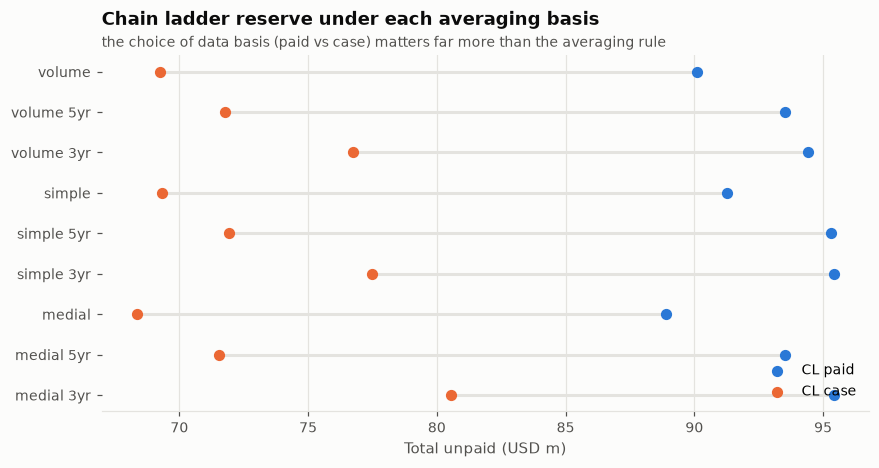

,CL paid unpaid,CL case unpaid,spread paid vs case
volume,"90,088","69,235","20,853"
volume 5yr,"93,526","71,792","21,734"
volume 3yr,"94,428","76,744","17,683"
simple,"91,261","69,342","21,919"
simple 5yr,"95,302","71,925","23,376"
simple 3yr,"95,421","77,488","17,933"
medial,"88,902","68,339","20,563"
medial 5yr,"93,518","71,532","21,986"
medial 3yr,"95,427","80,564","14,863"


In [7]:
impact = pd.DataFrame({
    "CL paid unpaid": [cl_unpaid(paid, fc_paid.iloc[i], cfg.TAIL_PAID) for i in range(len(fc_paid))],
    "CL case unpaid": [cl_unpaid(case, fc_case.iloc[i], cfg.TAIL_CASE) for i in range(len(fc_case))],
}, index=fc_paid.index)
impact["spread paid vs case"] = impact["CL paid unpaid"] - impact["CL case unpaid"]

fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(impact))
ax.scatter(impact["CL paid unpaid"] / 1e3, y, color=PL.COLOURS["CL paid"], s=40, label="CL paid", zorder=3)
ax.scatter(impact["CL case unpaid"] / 1e3, y, color=PL.COLOURS["CL case"], s=40, label="CL case", zorder=3)
for i in y:
    ax.plot([impact["CL case unpaid"].iloc[i] / 1e3, impact["CL paid unpaid"].iloc[i] / 1e3], [i, i], color=PL.GRID, lw=2, zorder=1)
ax.set_yticks(y, impact.index)
ax.invert_yaxis()
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.set_xlabel("Total unpaid (USD m)")
ax.set_title("Chain ladder reserve under each averaging basis")
PL.subtitle(ax, "the choice of data basis (paid vs case) matters far more than the averaging rule")
ax.legend(loc="lower right")
PL.save(fig, "03_factor_basis_impact")
plt.show()
impact.style.format("{:,.0f}")

**Reading this:**

* Within each basis, the three all-year averages agree to within ~$1-2m. **Shorter windows push both reserves up**, by up to ~$5m on paid and ~$11m on case, because the recent years developed more at ages 2-4 (the same post-1993 shift).
* **Between bases the gap is $15-23m on every rule.** No averaging choice reconciles paid and case. The disagreement is structural (notebook 02), so it's handled at the method-selection stage (notebook 08), not by tinkering with factors.
* **Selected: all-year volume-weighted for both bases.** It's the least noisy, it's the basis the Mack and bootstrap models assume, and the recent-year shift is better handled explicitly than by quietly shortening the window. The 5-year and 3-year results are kept as sensitivities.

## 3. Comparison with industry factors

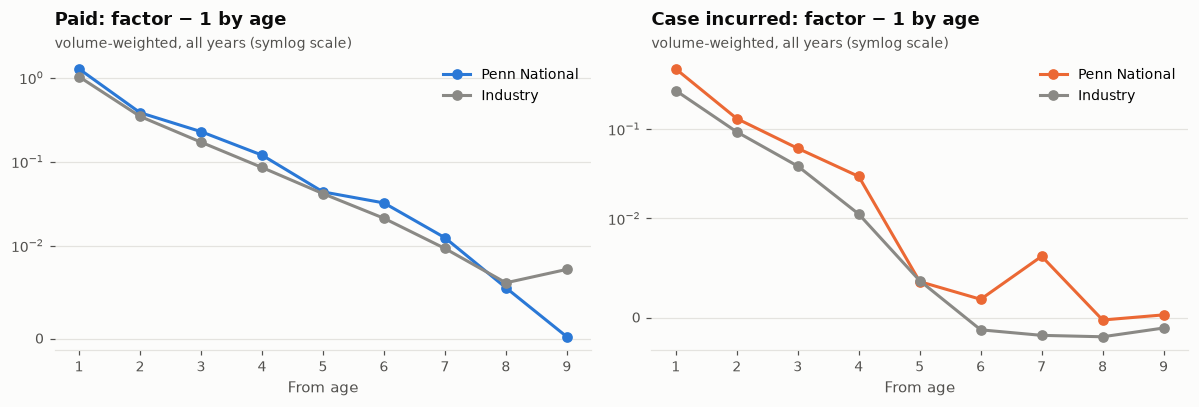

age,1,2,3,4,5,6,7,8,9
paid: company,2.270,1.383,1.228,1.119,1.044,1.032,1.012,1.005,1.000
paid: industry,2.026,1.346,1.170,1.085,1.042,1.021,1.010,1.006,1.007
case: company,1.471,1.131,1.061,1.030,1.004,1.002,1.006,1.000,1.000
case: industry,1.269,1.093,1.038,1.011,1.004,0.999,0.998,0.998,0.999


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, tri, itri, name, col in [(axes[0], paid, ind.paid, "Paid", PL.SERIES[0]), (axes[1], case, ind.case, "Case incurred", PL.SERIES[1])]:
    c = average_factors(tri) - 1
    i = average_factors(itri) - 1
    ax.plot(c.index, c.values, marker="o", color=col, label="Penn National")
    ax.plot(i.index, i.values, marker="o", color=PL.NEUTRAL, label="Industry")
    ax.set_yscale("symlog", linthresh=0.01)
    ax.set_title(f"{name}: factor − 1 by age")
    PL.subtitle(ax, "volume-weighted, all years (symlog scale)")
    ax.set_xlabel("From age")
    ax.legend()
fig.tight_layout()
PL.save(fig, "03_factors_vs_industry")
plt.show()
pd.DataFrame({"paid: company": average_factors(paid), "paid: industry": average_factors(ind.paid),
              "case: company": average_factors(case), "case: industry": average_factors(ind.case)}).T.style.format("{:.3f}")

Penn National develops **more slowly** than the industry on both bases (age 1→2 paid 2.27 vs 2.03, case 1.47 vs 1.27). Its case reserves at early ages are less complete than the industry average, which is consistent with a regional book with more bodily injury exposure. The company's own factors are credible (ten years of a ~$45m book), so I use them. The industry is used as a **reasonableness check and for the tail**, where the company's own data runs out.

## 4. Tail factor

Development after age 10 isn't observed. Three pieces of evidence:

1. **Curve fits** to the company's factors: inverse power, f − 1 = a·t^(−b) (Sherman, 1984), which decays slowly and gives a heavier tail, and exponential decay, which gives a lighter one.
2. **Industry evidence:** for the industry's 1988 accident year (fully observed to age 10), the ratio of reported incurred (case + IBNR) to paid at age 10. That is the industry's own estimate of what remains after 10 years.
3. **Line of business:** commercial auto is short-to-medium tailed. Very little should remain after 10 years.

In [9]:
f_paid, f_case = average_factors(paid), average_factors(case)
fits = {
    ("paid", "inverse power"): fit_tail(f_paid, "inverse_power", fit_from=2),
    ("paid", "exponential"): fit_tail(f_paid, "exponential", fit_from=2),
    ("case", "inverse power"): fit_tail(f_case, "inverse_power", fit_from=1),
    ("case", "exponential"): fit_tail(f_case, "exponential", fit_from=1),
}
tail_tbl = pd.DataFrame({k: {"tail factor": v.tail_factor, "R²": v.r2, "ages fitted": f"{min(v.fit_ages)}-{max(v.fit_ages)}"} for k, v in fits.items()}).T
ind_full = ind.reported_full.values[10] / ind.paid_full.values[10]
ind_case_full = ind.reported_full.values[10] / ind.case_full.values[10]
print(f"Industry 1988 AY at age 10: reported/paid = {ind_full.loc[1988]:.4f}, reported/case = {ind_case_full.loc[1988]:.4f}")
tail_tbl

Industry 1988 AY at age 10: reported/paid = 1.0042, reported/case = 1.0013


tail factor    R² ages fitted
paid inverse power       1.005 0.781         2-9
     exponential         1.001 0.897         2-9
case inverse power       1.003 0.880         1-9
     exponential         1.000 0.917         1-9

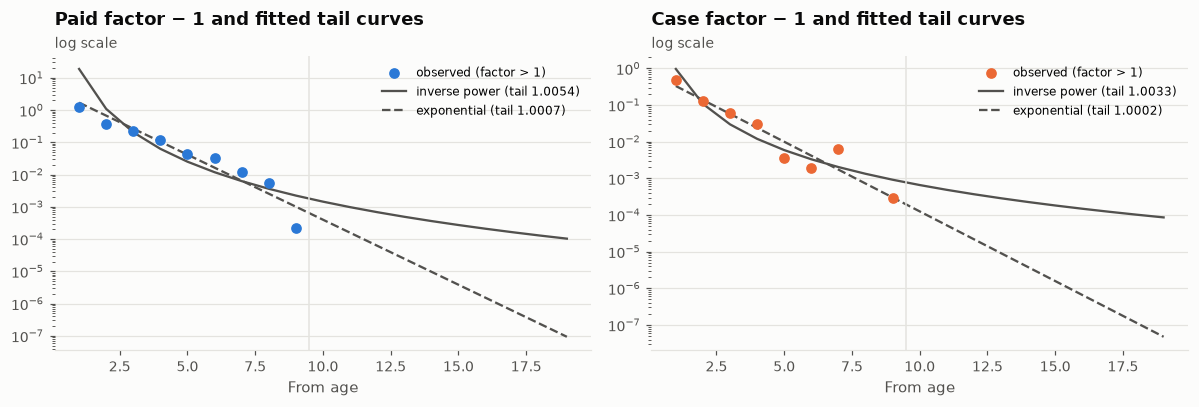

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ages = np.arange(1, 20)
for ax, f, name, col in [(axes[0], f_paid, "paid", PL.SERIES[0]), (axes[1], f_case, "case", PL.SERIES[1])]:
    obs = f[f > 1]
    ax.scatter(obs.index, obs - 1, color=col, zorder=3, label="observed (factor > 1)")
    for (b, curve), ls in zip([(name, "inverse power"), (name, "exponential")], ["-", "--"]):
        t = fits[(b, curve)]
        ax.plot(ages, [t.factor_at(a) - 1 for a in ages], ls=ls, color=PL.INK_2, lw=1.5, label=f"{curve} (tail {t.tail_factor:.4f})")
    ax.axvline(9.5, color=PL.GRID, lw=1)
    ax.set_yscale("log")
    ax.set_title(f"{name.capitalize()} factor − 1 and fitted tail curves")
    PL.subtitle(ax, "log scale")
    ax.set_xlabel("From age")
    ax.legend(fontsize=8)
fig.tight_layout()
PL.save(fig, "03_tail_fits")
plt.show()

**Selected tail factors:** paid **1.005**, case incurred **1.002**.

* The curve fits give 1.001-1.005 (paid) and 1.000-1.003 (case). The exponential fits are lighter.
* The industry still expected ~0.4% more on top of paid after 10 years, and ~0.1% on top of case.
* So I select **the inverse-power fit for paid (just above the industry's 1.004) and the midpoint of the fits for case (above the industry's 1.001)**. A curve fitted to a few small factors is fragile, and the inverse-power form is the more prudent of the two.

The tail is small for this line, but its sensitivity is shown so the reader can see it isn't a hidden driver:

In [11]:
sens = pd.DataFrame({
    "paid tail": [1.000, 1.005, 1.010, 1.020],
    "CL paid unpaid": [cl_unpaid(paid, f_paid, t) for t in [1.000, 1.005, 1.010, 1.020]],
    "case tail": [1.000, 1.002, 1.010, 1.020],
    "CL case unpaid": [cl_unpaid(case, f_case, t) for t in [1.000, 1.002, 1.010, 1.020]],
}, index=["none", "selected", "+1%", "+2%"])
sens.style.format({"paid tail": "{:.3f}", "case tail": "{:.3f}", "CL paid unpaid": "{:,.0f}", "CL case unpaid": "{:,.0f}"})

,paid tail,CL paid unpaid,case tail,CL case unpaid
none,1.000,"88,272",1.000,"68,548"
selected,1.005,"90,088",1.002,"69,235"
+1%,1.010,"91,905",1.010,"71,984"
+2%,1.020,"95,537",1.020,"75,419"


Each extra 1% of tail adds roughly $3.5m, because it applies to the *whole* ultimate, including fully paid years. That's why a tail is never something to round up casually on a long-tailed line. Here the evidence supports a small one.

## 5. Selected factors

In [12]:
c_paid, c_case = cdfs(f_paid, cfg.TAIL_PAID), cdfs(f_case, cfg.TAIL_CASE)
sel = pd.DataFrame({
    "paid LDF": list(f_paid) + [cfg.TAIL_PAID],
    "paid CDF": c_paid.values,
    "paid % developed": 1 / c_paid.values,
    "case LDF": list(f_case) + [cfg.TAIL_CASE],
    "case CDF": c_case.values,
    "case % developed": 1 / c_case.values,
}, index=[f"{a}-{a+1}" for a in f_paid.index] + ["10-ult (tail)"])
sel.style.format({c: "{:.4f}" for c in sel.columns if "DF" in c} | {c: "{:.1%}" for c in sel.columns if "%" in c})

,paid LDF,paid CDF,paid % developed,case LDF,case CDF,case % developed
1-2,2.2702,4.7551,21.0%,1.4707,1.8416,54.3%
2-3,1.3828,2.0945,47.7%,1.1310,1.2522,79.9%
3-4,1.2275,1.5147,66.0%,1.0608,1.1072,90.3%
4-5,1.1195,1.2339,81.0%,1.0295,1.0437,95.8%
5-6,1.0436,1.1022,90.7%,1.0036,1.0138,98.6%
6-7,1.0322,1.0562,94.7%,1.0019,1.0101,99.0%
7-8,1.0124,1.0233,97.7%,1.0062,1.0083,99.2%
8-9,1.0055,1.0107,98.9%,0.9998,1.0021,99.8%
9-10,1.0002,1.0052,99.5%,1.0003,1.0023,99.8%
10-ult (tail),1.0050,1.0050,99.5%,1.0020,1.0020,99.8%


## Conclusions → next steps

* **Factors:** all-year volume-weighted on both bases, no exclusions. The flagged 1993-94 case ratios are kept because they may be the start of a trend.
* **Tail:** paid 1.005, case 1.002, supported by curve fits and industry data. Tail sensitivity is small.
* **The averaging rule is a second-order issue.** The ~$20m gap between paid and case projections survives every choice of factors. That gap is the central judgement of this review, taken up in notebooks 04-08.
* At age 1 only **~21% is paid** but **~54% is case-reported**. A paid chain ladder multiplies the 1997 paid figure by ~4.8, so a small error in early paid factors is hugely leveraged. This is the motivation for BF-type methods on recent years.